
# 自転車盗は何時に多く発生しているのか？

## グループ02

- 長谷川 大祐
- 三橋 龍之輔
- 山本 雄輝

## 1. 調べたいこと

千葉県では、自転車盗がどの時間帯に多く発生しているのかを調べる。

0時から23時までの発生件数を集計し、棒グラフで比較する。特に多かった時間帯については、地域や発生場所にも注目し、盗難を減らすための対策を考える。

## 2. 使用するデータ

- 出典：千葉県警察のオープンデータ
- 使用ファイル：bike.csv
- 対象：2025年（令和7年）公開分の自転車盗データ
- データ件数：10,054件


In [11]:
# 読み込むファイルを設定する（Notebookと同じフォルダに保存）
filename = "bike.csv"
encoding = "cp932"

# 千葉県警のCSVはShift-JIS（CP932）。追加インストールは不要
import csv
with open(filename, encoding=encoding, newline="") as file:
    incidents = list(csv.DictReader(file))

# 1行が1件の事件。件数を確認する
len(incidents)

10054

【時間帯別の盗難件数】
00時：180件
01時：74件
02時：35件
03時：27件
04時：29件
05時：141件
06時：359件
07時：901件
08時：706件
09時：436件
10時：430件
11時：390件
12時：442件
13時：476件
14時：419件
15時：462件
16時：697件
17時：877件
18時：879件
19時：607件
20時：461件
21時：392件
22時：315件
23時：216件

時間が分かる件数：9951件
時間が不明な件数：103件
合計：10054件

【盗難件数が多い時間帯TOP5】
1位：07時台（901件）
2位：18時台（879件）
3位：17時台（877件）
4位：08時台（706件）
5位：16時台（697件）


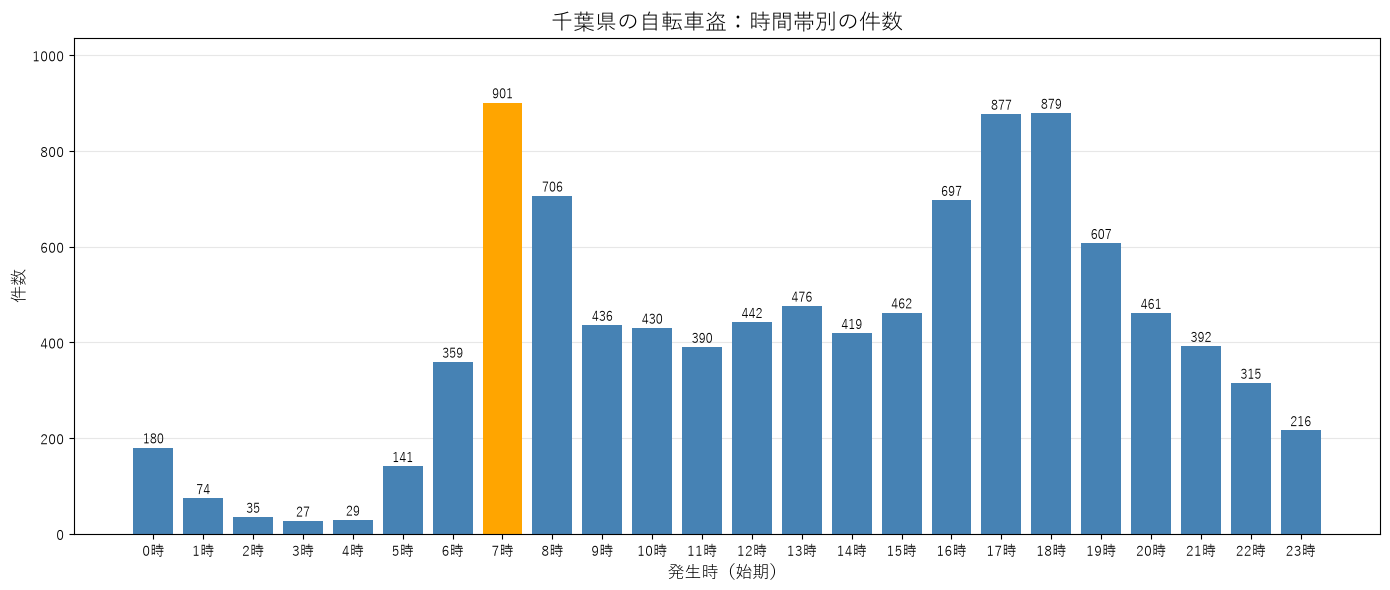


【分析結果】
最も件数が多い時間帯： 7時台
最多件数：901件
時間が分かる記録のうち9.1%


In [12]:

# 自転車盗の時間帯別件数を調べる
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 日本語が文字化けしないようにする
fonts = {f.name for f in font_manager.fontManager.ttflist}
for font in ["Yu Gothic", "Meiryo", "MS Gothic"]:
    if font in fonts:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False

# 0時から23時までの件数を用意する
hour_counts = {h: 0 for h in range(24)}
unknown = 0

# CSVの発生時刻を1件ずつ確認する
for incident in incidents:
    value = str(incident["発生時（始期）"]).strip()

    if value.isdigit() and 0 <= int(value) <= 23:
        hour = int(value)
        hour_counts[hour] += 1
    else:
        unknown += 1

# 集計結果を表示する
print("【時間帯別の盗難件数】")
for hour in range(24):
    print(f"{hour:02d}時：{hour_counts[hour]}件")

known = sum(hour_counts.values())
print(f"\n時間が分かる件数：{known}件")
print(f"時間が不明な件数：{unknown}件")
print(f"合計：{known + unknown}件")

# 件数の多い時間帯TOP5
ranking = sorted(hour_counts.items(),
                 key=lambda x: x[1], reverse=True)

print("\n【盗難件数が多い時間帯TOP5】")
for rank, (hour, count) in enumerate(ranking[:5], 1):
    print(f"{rank}位：{hour:02d}時台（{count}件）")

# 棒グラフを作成する
if known > 0:
    max_count = max(hour_counts.values())
    peak_hours = [h for h in range(24)
                  if hour_counts[h] == max_count]

    colors = ["orange" if h in peak_hours else "steelblue"
              for h in range(24)]

    fig, ax = plt.subplots(figsize=(14, 6))
    bars = ax.bar(
        range(24),
        [hour_counts[h] for h in range(24)],
        color=colors
    )

    ax.set_title("千葉県の自転車盗：時間帯別の件数", fontsize=16)
    ax.set_xlabel("発生時（始期）", fontsize=12)
    ax.set_ylabel("件数", fontsize=12)
    ax.set_xticks(range(24))
    ax.set_xticklabels([f"{h}時" for h in range(24)])
    ax.set_ylim(0, max_count * 1.15)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    for bar, count in zip(bars, hour_counts.values()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max_count * 0.01,
            str(count),
            ha="center",
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

    print("\n【分析結果】")
    print("最も件数が多い時間帯：",
          "、".join(f"{h}時台" for h in peak_hours))
    print(f"最多件数：{max_count}件")
    print(f"時間が分かる記録のうち"
          f"{max_count / known * 100:.1f}%")


In [13]:

# CSVにどんなデータ項目があるか確認する
print("【CSVの項目一覧】")
for i, column in enumerate(incidents[0].keys(), 1):
    print(f"{i}. {column}")


【CSVの項目一覧】
1. 罪名
2. 手口
3. 管轄警察署（発生地）
4. 管轄交番・駐在所（発生地）
5. 市区町村コード（発生地）
6. 都道府県（発生地）
7. 市区町村（発生地）
8. 町丁目（発生地）
9. 発生年月日（始期）
10. 発生時（始期）
11. 発生場所
12. 発生場所の詳細
13. 被害者の年齢
14. 被害者の職業
15. 施錠関係


In [14]:

# 7時・17時・18時に盗難が多い場所を調べる

target_hours = [7, 17, 18]

for target_hour in target_hours:
    place_counts = {}

    for incident in incidents:
        hour_text = incident["発生時（始期）"].strip()

        if hour_text.isdigit() and int(hour_text) == target_hour:
            place = incident["発生場所"].strip()

            if not place:
                place = "不明"

            if place not in place_counts:
                place_counts[place] = 0

            place_counts[place] += 1

    ranking = sorted(
        place_counts.items(),
        key=lambda x: x[1],
        reverse=True
    )

    print(f"\n【{target_hour}時台の盗難場所 TOP5】")
    for rank, (place, count) in enumerate(ranking[:5], 1):
        print(f"{rank}位：{place}（{count}件）")



【7時台の盗難場所 TOP5】
1位：駐車（輪）場（511件）
2位：その他（266件）
3位：その他の住宅（３階建て以下共同住宅等）（44件）
4位：一戸建住宅（31件）
5位：道路上（30件）

【17時台の盗難場所 TOP5】
1位：その他（302件）
2位：駐車（輪）場（219件）
3位：その他の住宅（３階建て以下共同住宅等）（145件）
4位：４階建て以上共同住宅（105件）
5位：一戸建住宅（66件）

【18時台の盗難場所 TOP5】
1位：その他（263件）
2位：駐車（輪）場（213件）
3位：４階建て以上共同住宅（134件）
4位：その他の住宅（３階建て以下共同住宅等）（133件）
5位：一戸建住宅（95件）


In [15]:

# 「その他」に分類された場所の詳細を調べる

for target_hour in [7, 17, 18]:
    detail_counts = {}

    for incident in incidents:
        hour = incident["発生時（始期）"].strip()
        place = incident["発生場所"].strip()

        if hour.isdigit() and int(hour) == target_hour:
            if place == "その他":
                detail = incident["発生場所の詳細"].strip()

                if not detail:
                    detail = "不明・記載なし"

                if detail not in detail_counts:
                    detail_counts[detail] = 0

                detail_counts[detail] += 1

    ranking = sorted(
        detail_counts.items(),
        key=lambda x: x[1],
        reverse=True
    )

    print(f"\n【{target_hour}時台：「その他」の詳細 TOP5】")

    for rank, (detail, count) in enumerate(ranking[:5], 1):
        print(f"{rank}位：{detail}（{count}件）")



【7時台：「その他」の詳細 TOP5】
1位：駐車（輪）場（232件）
2位：その他（34件）

【17時台：「その他」の詳細 TOP5】
1位：駐車（輪）場（238件）
2位：その他（64件）

【18時台：「その他」の詳細 TOP5】
1位：駐車（輪）場（208件）
2位：その他（55件）


In [16]:

# 駐車（輪）場での盗難について施錠状況を調べる

for target_hour in [7, 17, 18]:
    lock_counts = {}

    for incident in incidents:
        hour = incident["発生時（始期）"].strip()
        place = incident["発生場所"].strip()
        detail = incident["発生場所の詳細"].strip()

        if not hour.isdigit() or int(hour) != target_hour:
            continue

        # 駐車（輪）場に該当する記録だけを調べる
        is_parking = (
            place == "駐車（輪）場"
            or (place == "その他" and detail == "駐車（輪）場")
        )

        if is_parking:
            lock = incident["施錠関係"].strip()

            if not lock:
                lock = "不明"

            lock_counts[lock] = lock_counts.get(lock, 0) + 1

    total = sum(lock_counts.values())

    print(f"\n【{target_hour}時台の駐車（輪）場】")
    print(f"合計：{total}件")

    for lock, count in lock_counts.items():
        percentage = count / total * 100 if total else 0
        print(f"{lock}：{count}件（{percentage:.1f}%）")



【7時台の駐車（輪）場】
合計：743件
施錠した：236件（31.8%）
施錠せず：507件（68.2%）

【17時台の駐車（輪）場】
合計：457件
施錠せず：317件（69.4%）
施錠した：140件（30.6%）

【18時台の駐車（輪）場】
合計：421件
施錠した：130件（30.9%）
施錠せず：291件（69.1%）



## 3. 分析して分かったこと

### 発見① 朝と夕方に盗難の記録が多い

時間帯別に集計した結果、7時台が901件で最も多かった。次に18時台が879件、17時台が877件だった。

夜中よりも朝や夕方に件数が多かったのは意外だった。ただし、今回使ったのは発生時（始期）のデータなので、必ずしもその時間に盗まれたとは限らない。

### 発見② 7時台は駐車（輪）場の割合が高い

7時台の901件のうち、743件が駐車（輪）場として集計された。これは約82.5%にあたる。

17時台では457件（約52.1%）、18時台では421件（約47.9%）だった。時間帯によって、盗難が記録された場所の傾向に違いがあることが分かった。

### 発見③ 駐車（輪）場では無施錠の割合が高い

駐車（輪）場の盗難記録を調べると、無施錠の割合は7時台が68.2%、17時台が69.4%、18時台が69.1%だった。

どの時間帯でも約7割が無施錠だったことから、鍵をかけずに自転車を止めているケースが多いと分かった。

## 4. 防犯対策の提案

駐輪場での無施錠を減らすために、出入口などの目立つ場所に施錠を呼びかける看板を設置することを提案する。

また、朝や夕方に駐輪場を利用する人に向けて、鍵のかけ忘れを防ぐ呼びかけを行うとよいと考えた。

今回のデータだけでは対策の効果までは分からないが、盗難記録の多い場所や時間帯に合わせた呼びかけができると思う。

## 5. 分析の限界

今回のデータは2025年の公開分だが、過去の発生年や不明な記録も含まれている。また、発生時（始期）は実際に盗まれた瞬間の時刻とは限らない。

さらに、盗難件数だけでは利用者数や駐輪台数の違いを考慮できないため、特定の時間帯や場所が最も危険だと断定することはできない。
時間帯別に集計した9,951件と、発生時刻が不明な103件を合わせると10,054件になり、元データの件数と一致した。